In [3]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

### Linear regression

So for the linear regression with one input variable, I need to find parameters weight and bias. And I need to optimize does parameters for lowest mean square error:
- **w** and **b** paprameters
- **mean square error** for measuring how prices results paramters gives

Function **L** represent mean square error, and goal is to find the lowest value

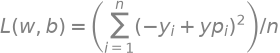

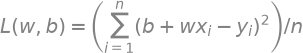

In [ ]:
sp.init_printing()

w, b, rows = sp.symbols('w b n')
i = sp.symbols('i')
x = sp.IndexedBase('x')
y = sp.IndexedBase('y')
y_pred = sp.IndexedBase('yp')

L = sp.Sum((w*x[i] + b - y[i])**2, (i, 1, rows)) / rows

display(sp.Eq(sp.Function('L')(weight, bias), sp.Sum((y_pred[i] - y[i])**2, (i, 1, rows)) / rows))
display(sp.Eq(sp.Function('L')(weight, bias), L))


#### Simple test example

In [4]:
x = np.array([0, 1])
y = np.array([1, 3])

mse = np.mean((y - (x * 2.0 + 1))**2)

print(mse)

0.0


Formulas are shown in below cells.

- This becomes multivarible fucntion with partial derivatives

So the gradient, direction of the steepest increase is **[w + b - 3, w + 2b - 4]**, and therfore for steepes descent is the oppsotie direction:
- at (0,0) gradient descent is [-3, -4]
- we also need learing rate which can be alpha = 0.1
- so next position is [0,0] - 0.1 [-3, -4]

In [ ]:
weight, bias = sp.symbols('w b')

L = ((bias - 1)**2 + (weight + bias - 3)**2) / 2

display(sp.Eq(sp.Function('L')(weight, bias), L))

In [18]:
dl_dw = sp.diff(L, weight)
dl_db = sp.diff(L, bias)

display(sp.Eq(sp.Derivative(L, weight), dl_dw))
display(sp.Eq(sp.Derivative(L, bias), dl_db))

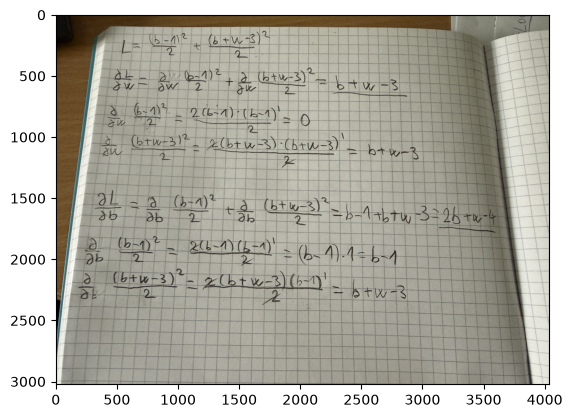

In [28]:
# chain rule

# MISTAKE !!! : last row is not (b - 1)' but (b + w - 3)'

image = np.array(plt.imread('data/images/PD1.jpg'))

plt.imshow(image)
plt.show()

In [24]:
gradient = sp.Matrix([dl_dw, dl_db])

display(sp.Eq(
    sp.Symbol(r'\nabla L'),
    gradient,
    evaluate=False
))

           ⎡ b + w - 3 ⎤
\nabla L = ⎢           ⎥
           ⎣2⋅b + w - 4⎦

In [25]:
point = {w: 0, b: 0}

gradient_at_point = gradient.subs(point)

display(gradient_at_point)

⎡-3⎤
⎢  ⎥
⎣-4⎦

In [17]:
# addtional representations

lhs = sp.Symbol(r'\frac{\partial L}{\partial w}')

display(sp.Eq(lhs, dl_dw))

display(sp.Eq(sp.Derivative(sp.Function('F')(weight, bias), weight), dl_dw))
display(sp.Eq(sp.Derivative(sp.Function('F')(weight, bias), weight), dl_db))

Let's iterate to find smalles square error

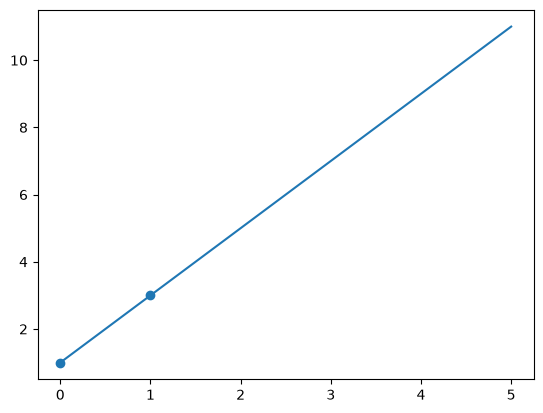

In [ ]:
plt.scatter(x, y)

line_x = np.array([0, 5])
line_y = 2 * line_x + 1

plt.plot(line_x, line_y)

plt.show()

### TO DO : show 3d graph of function

# General formula for calcualting partial deriatives

Let's again see forula for square loss function below. From there we can derive formulas for partial derivatives for w and b. And then for when for multiple columns - therfore mutiple weights

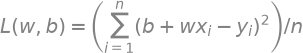

In [30]:
display(sp.Eq(sp.Function('L')(weight, bias), L))

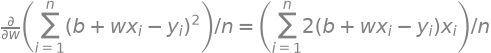

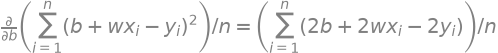

In [31]:
dl_dw = sp.diff(L, weight)
dl_db = sp.diff(L, bias)

display(sp.Eq(sp.Derivative(L, weight), dl_dw))
display(sp.Eq(sp.Derivative(L, bias), dl_db))

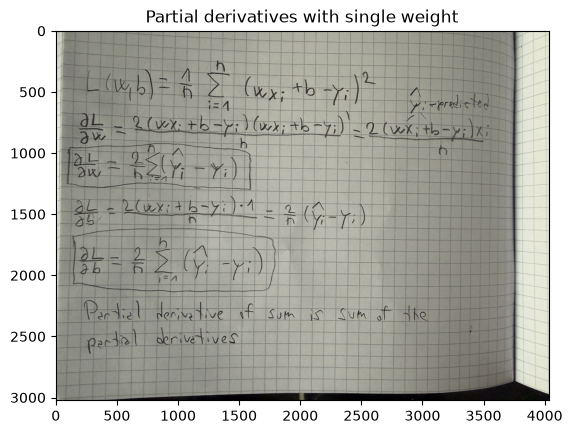

In [35]:
pd2 = np.array(plt.imread('data/images/PD2.jpg'))

plt.imshow(pd2)
plt.title("Partial derivatives with single weight")
plt.show()

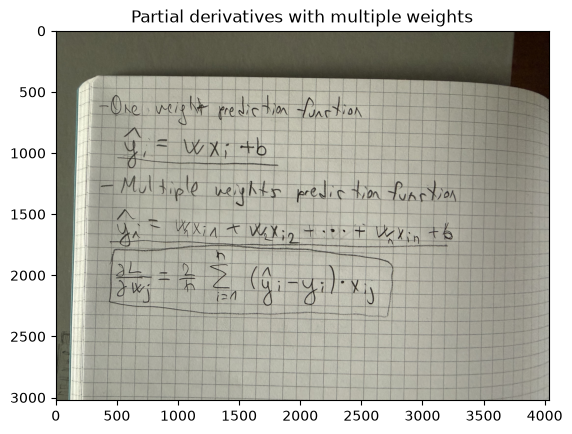

In [36]:
pd3 = np.array(plt.imread('data/images/PD3.jpg'))

plt.imshow(pd3)
plt.title("Partial derivatives with multiple weights")
plt.show()

#### More concrete example

In [ ]:
max_temperatures = [20.3, 19.9, 17.3, 20.0, 15.4, 12.0]
iced_coffees = [43, 34, 33, 44, 25, 23]

In [ ]:
plt.scatter(max_temperatures, iced_coffees)

plt.show()

In [ ]:
# initail values of parameter

b = 0
w = 0 

max_terations = 1000

def predict(x):
    return x * w + b


mse = np.mean([(ic - predict(ic))**2  for ic in iced_coffees])

print(mse)